# Avaliação Textual e Visualização do WikiText-2
por Letícia Ramos de Oliveira.

### SUMÁRIO:

1. Exploração do dataset.

   
3. Pesquisa e implementação de métricas + Visualizações.

   
5. Análise crítica e Conclusões.

### 1. Exploração do Dataset

Incialmente, os arquivos disponíveis foram instalados pelo terminal através do seguinte código:

In [ ]:
pip install datasets

python -c "
from datasets import load_dataset
ds = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1')
for split in ['train', 'validation', 'test']:
    with open(f'wiki2_{split}.txt', 'w', encoding='utf-8') as f:
        f.write(''.join(ds[split]['text']))
print(ds)
"

Após isso, decidi seguir o passo a passo a seguir:

#### *1.1. Estrutura e organização*
Inspecionei os arquivos e vi que cada linha é um parágrafo, um título ou uma linha vazia. Os títulos usam sinais de igual: = Título = marca um artigo e = = Seção = = marca uma seção. O texto já vem tokenizado, com a pontuação separada por espaços e marcações como @-@. Ademais, tentei ao máximo seguir a estrutura proposta por Build a Large Language Model from Scratch [1], utilizando, assim, o código fornecido por ele de forma adaptada.

#### *1.2. Separação dos artigos*

Para separar os artigos, identifiquei os títulos de nível 1 (formato ` = Título = `) com uma expressão regular e agrupei todas as linhas seguintes no mesmo artigo até o próximo título de nível 1. Títulos de nível 2 ou mais (` = = Seção = = `) foram tratados como divisões internas do artigo. Para validar a separação, conferi o número de artigos por partição, verifiquei se havia artigos vazios e inspecionei manualmente uma amostra aleatória de três artigos por partição.

**Tabela 1 – Artigos e títulos por partição**

| Partição | Artigos | Artigos vazios | Títulos nível 1 | Nível 2 (seções) | Nível 3 (subseções) | Nível 4+ | Títulos de seção por artigo* |
|---|---:|---:|---:|---:|---:|---:|---:|
| Treino | 629 | 0 | 629 | 2.922 | 2.346 | 314 | 8,9 |
| Validação | 60 | 0 | 60 | 301 | 237 | 22 | 9,3 |
| Teste | 62 | 0 | 62 | 302 | 298 | 44 | 10,4 |
| **Total** | **751** | **0** | **751** | **3.525** | **2.881** | **380** | **9,0** |

\*Soma dos títulos de nível 2, 3 e 4+, dividida pelo número de artigos.

**Tabela 2 – Títulos de seção mais comuns (treino)**

| Posição | Título da seção | Ocorrências |
|---:|---|---:|
| 1 | History | 129 |
| 2 | Reception | 112 |
| 3 | Background | 95 |
| 4 | Plot | 63 |
| 5 | Production | 63 |
| 6 | Legacy | 43 |
| 7 | Description | 40 |
| 8 | Critical reception | 37 |
| 9 | Development | 34 |
| 10 | Early life | 32 |

**Tabela 3 – Amostra de artigos usada na validação manual**

| Partição | Título | Linhas não vazias | Palavras |
|---|---|---:|---:|
| Treino | Architecture of the Song dynasty | 41 | 4.542 |
| Treino | Gold dollar | 40 | 4.764 |
| Treino | History of Braathens SAFE (1946–93) | 69 | 9.262 |
| Validação | The Same Old Story | 18 | 2.019 |
| Validação | Calvin McCarty | 42 | 2.574 |
| Validação | Frank Headlam | 19 | 2.631 |
| Teste | Manila | 153 | 10.278 |
| Teste | Hed PE | 55 | 2.131 |
| Teste | Du Fu | 56 | 4.662 |

### Análise

A separação não gerou nenhum artigo vazio. Na amostra, todos os artigos começam com um parágrafo introdutório coerente com o título e terminam antes do título seguinte, o que indica que o agrupamento das linhas funcionou.

O número de artigos encontrado na validação (60) coincide com o descrito na literatura (MERITY et al., 2017) [3]. No treino (629) e no teste (62), porém, foi encontrado mais artigos do que os 600 e 60 descritos. Isso sugere que algumas linhas no formato de título de nível 1 não correspondem a artigos reais. 

#### *1.3. Distribuição de palavras, frases e artigos*
Para cada artigo, contei as palavras (separando por espaços) e as frases (separando pelo ponto final). Calculei média, mediana, desvio-padrão e valores extremos, e fiz histogramas e boxplots para visualizar as distribuições.


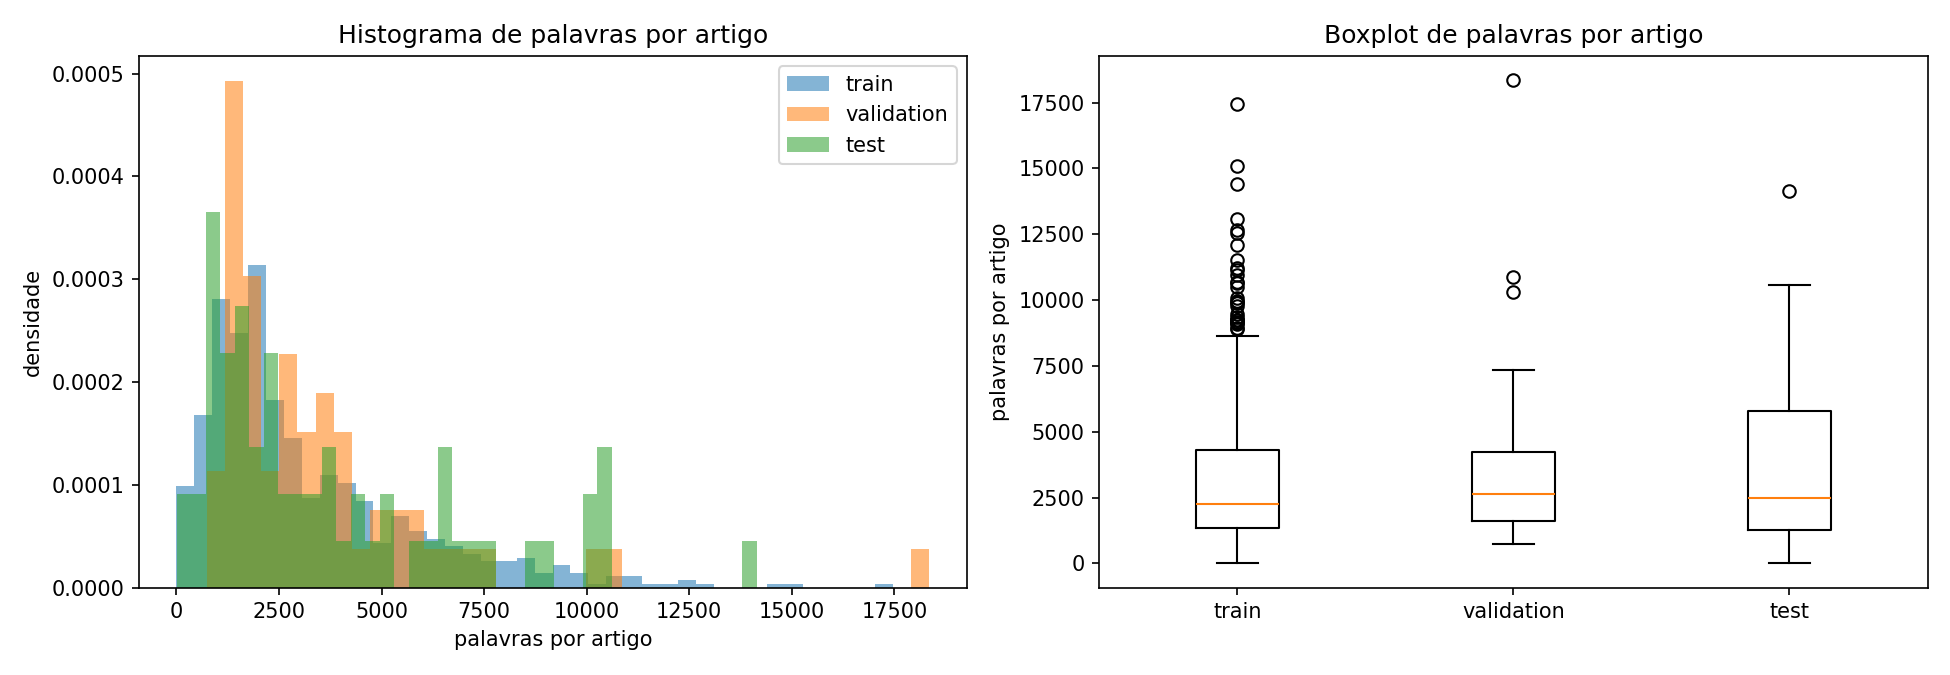

In [26]:
from IPython.display import Image, display

display(Image("atv2/dist_palavras.png", width=900))

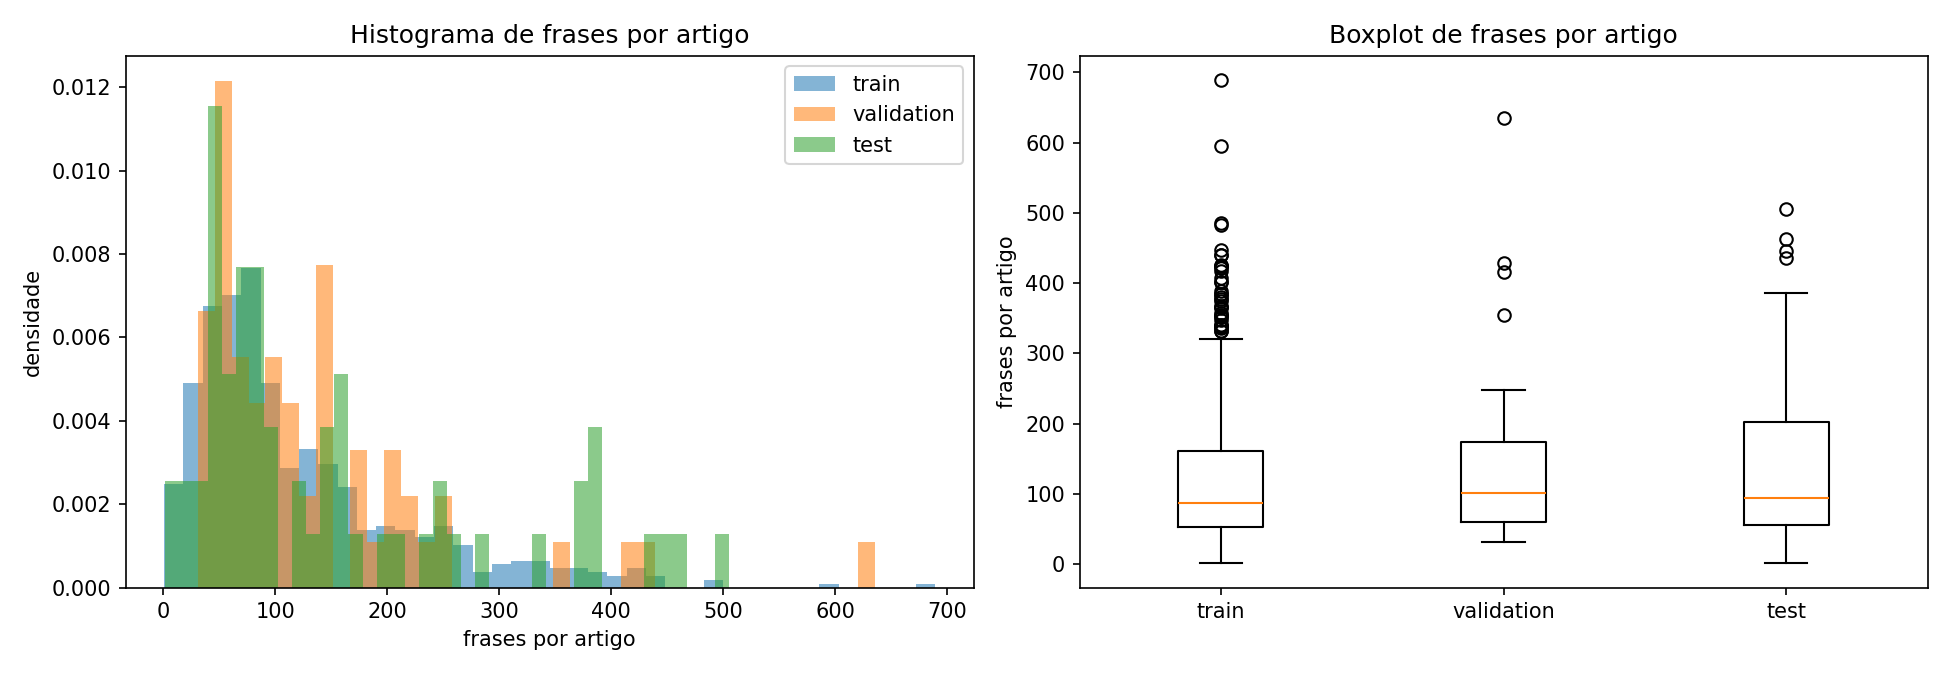

In [23]:
from IPython.display import Image, display

display(Image("atv2/dist_frases.png", width=900))

#### Análise


As Figuras de palavras e de frases por artigo mostram o mesmo padrão, o que é esperado: como o tamanho médio das frases é estável (cerca de 22 palavras), o número de frases acompanha de perto o número de palavras de cada artigo.

**Distribuição assimétrica.** Nas três partições, as distribuições são fortemente **assimétricas à direita**. A maioria dos artigos está concentrada entre cerca de 1.000 e 4.500 palavras (aproximadamente 50 a 200 frases), mas uma cauda longa se estende até mais de 17.000 palavras e quase 700 frases. Por causa dessa cauda, a média é sempre maior que a mediana: no treino, a média é de 2.723 palavras por artigo, enquanto a mediana fica em torno de 2.300. Por isso, a **mediana** descreve melhor um artigo "típico" do WikiText-2 do que a média.

**Comparação entre as partições.** As medianas são próximas nas três partições, com cerca de 2.300 palavras no treino e 2.500 a 2.650 na validação e no teste, e com 90 a 100 frases. Isso indica que os artigos têm, em geral, tamanhos comparáveis. As diferenças aparecem na dispersão:

- O **treino** tem muitos valores atípicos (*outliers*) acima de cerca de 8.500 palavras. Isso é natural, já que ele tem cerca de 10 vezes mais artigos e, portanto, mais chances de conter artigos muito longos.
- O **teste** tem a maior amplitude interquartil (de cerca de 1.300 a 5.800 palavras) e um histograma irregular, com picos isolados por volta de 6.500 e 10.500 palavras. Com apenas cerca de 60 artigos, poucos artigos longos bastam para formar esses picos e deslocar a média para cima (3.252 palavras).
- A **validação** tem a menor dispersão no centro da distribuição, mas também o maior artigo do corpus, com mais de 18.000 palavras.

Assim, as diferenças de média entre as partições (2.723, 2.992 e 3.252 palavras) se devem principalmente a **poucos artigos muito longos** nas partições pequenas, e não a uma diferença sistemática no tamanho dos artigos.

**Artigos muito curtos.** No treino e no teste, o valor mínimo é próximo de zero, enquanto na validação o menor artigo tem cerca de 750 palavras. Esses "artigos" quase vazios são coerentes com dois resultados anteriores: o número de artigos acima do esperado na separação (629 no treino e 62 no teste, em vez de 600 e 60) e os artigos para os quais o MTLD não pôde ser calculado (18 no treino, 1 no teste e nenhum na validação). Tudo indica que se trata de trechos curtos com formato de título de nível 1, e não de artigos reais.

**Implicações para o treino de modelos de linguagem.** A grande variação de tamanho tem consequências práticas:

- Mesmo o artigo típico (cerca de 2.300 palavras) é maior do que a janela de contexto de modelos pequenos. Por isso, os textos precisam ser divididos em sequências de tamanho fixo, por exemplo com uma janela deslizante.
- Como o número de sequências geradas é proporcional ao tamanho do artigo, os artigos longos **contribuem com muito mais exemplos de treino** do que os curtos. Um único artigo de 17.000 palavras pesa tanto quanto cerca de sete artigos típicos. Os temas desses artigos longos ficam, portanto, mais representados no que o modelo aprende do que a contagem de artigos sugere.
- Na avaliação, como o teste tem poucos artigos, a perplexidade calculada nele também pode ser influenciada por alguns poucos artigos longos.

Em resumo, as três partições têm distribuições de tamanho semelhantes no centro, o que confirma que são comparáveis entre si. As diferenças observadas vêm de valores extremos e do tamanho reduzido da validação e do teste.

#### *1.4. Frequência e vocabulário*
Contei a frequência das palavras no treino para obter o tamanho do vocabulário, as palavras mais comuns e a proporção de palavras que aparecem uma única vez. Fiz um gráfico log-log de frequência por rank para verificar a Lei de Zipf [2]. Também calculei a taxa de palavras da validação e do teste que não aparecem no treino.

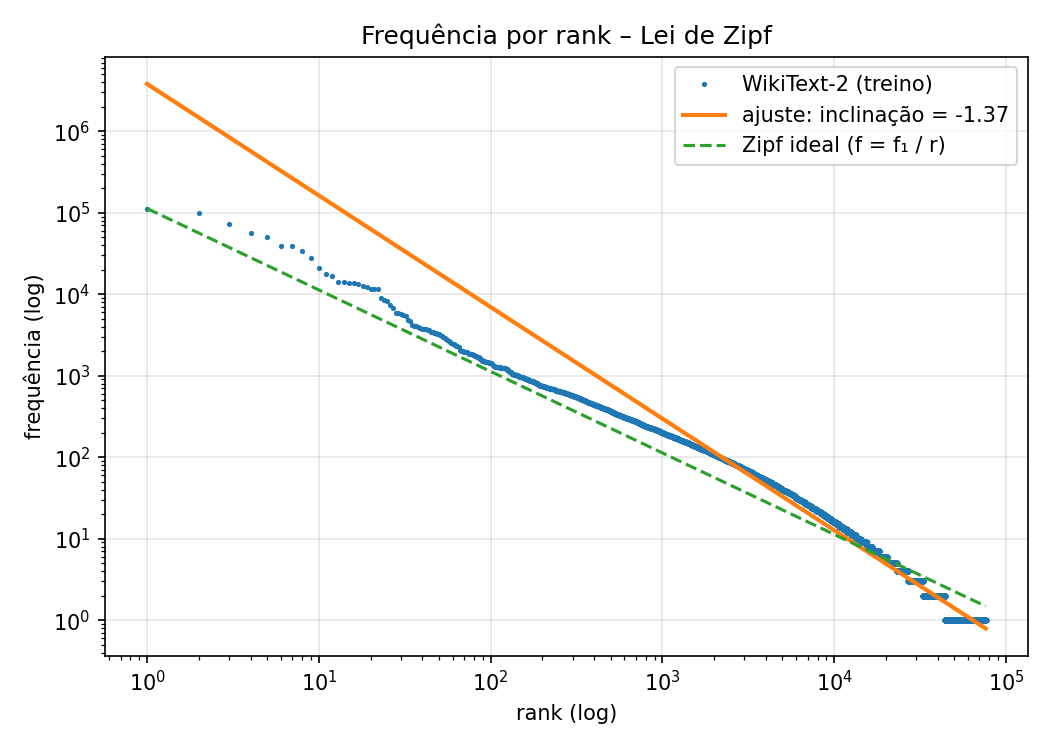

In [22]:
from IPython.display import Image, display

display(Image("atv2/zipf.png", width=600))

#### Análise


No WikiText-2, os pontos formam uma faixa quase retilínea ao longo de quatro ordens de grandeza do *rank*, de 10 a cerca de 20.000, praticamente **paralela à reta de Zipf ideal**. Isso confirma que o vocabulário do corpus segue a Lei de Zipf: poucas palavras são extremamente frequentes e a grande maioria é rara, como já indicavam as faixas de frequência (0,17% do vocabulário cobre 44,65% do texto).

Os desvios aparecem nas extremidades, como é comum em corpora reais:
- **No início** (*ranks* 1 a 20), a curva é mais "achatada" que a ideal: as palavras mais comuns têm frequências mais próximas entre si do que a lei prevê.
- **No final** (*rank* acima de 20.000), a curva cai abaixo da reta ideal e forma "degraus" horizontais. Os degraus correspondem às milhares de palavras com frequência exatamente 1, 2 ou 3. Como a frequência é um número inteiro, palavras raras não conseguem seguir uma curva contínua, e o tamanho finito do corpus limita a cauda.

A inclinação ajustada (−1,37) é mais íngreme que a esperada, mas não deve ser lida como um desvio real da lei. O ajuste por mínimos quadrados trata todos os *ranks* com o mesmo peso. Como a maioria dos pontos está na cauda (dezenas de milhares de palavras raras, contra poucas dezenas no início), a reta é "puxada" pelos degraus finais. Por isso, ela passa muito acima dos dados no início do gráfico. Na região central, onde a lei se aplica, os dados acompanham a inclinação −1 da reta ideal.

Em resumo, o WikiText-2 segue a Lei de Zipf na maior parte do vocabulário, com os desvios típicos nas extremidades. Esse comportamento explica a cauda longa de palavras raras, que motiva o uso do token `<unk>` e da tokenização por subpalavras em modelos de linguagem.

### 2. Pesquisa e implementação de métricas + Visualizações

#### *2.1. Diversidade lexical do dataset*

Para avaliar a variedade do vocabulário, usei três medidas de diversidade lexical:

- **TTR (*Type-Token Ratio*)**: razão entre o número de palavras distintas (*types*) e o total de palavras (*tokens*). É a medida mais simples, mas diminui à medida que o texto cresce, porque as palavras mais comuns passam a se repetir (efeito da Lei de Zipf). Por isso, não é adequada para comparar textos de tamanhos diferentes.

- **Distinct-N**: razão entre o número de n-gramas distintos e o total de n-gramas do texto. O Distinct-1 equivale ao TTR, e o Distinct-2 mede a variedade de pares de palavras consecutivas. Foi proposta para avaliar a diversidade de textos gerados por modelos de linguagem, sendo útil para detectar repetições (LI et al., 2016).

- **MTLD (*Measure of Textual Lexical Diversity*)**: percorre o texto calculando o TTR acumulado e, sempre que ele cai abaixo de 0,72, conta um "fator" e reinicia a contagem. O MTLD é o comprimento médio desses trechos, calculado nos dois sentidos do texto. Quanto maior o valor, mais diverso o vocabulário. Ao contrário do TTR, é pouco sensível ao tamanho do texto (MCCARTHY; JARVIS, 2010) [4].

| Medida | O que mede | Limitação |
|---|---|---|
| TTR | Variedade de palavras | Depende do tamanho do texto |
| Distinct-N | Variedade de sequências de *n* palavras | Também é sensível ao tamanho |
| MTLD | Variedade de palavras, corrigida pelo tamanho | Cálculo mais complexo |

O resultado obtido foi:

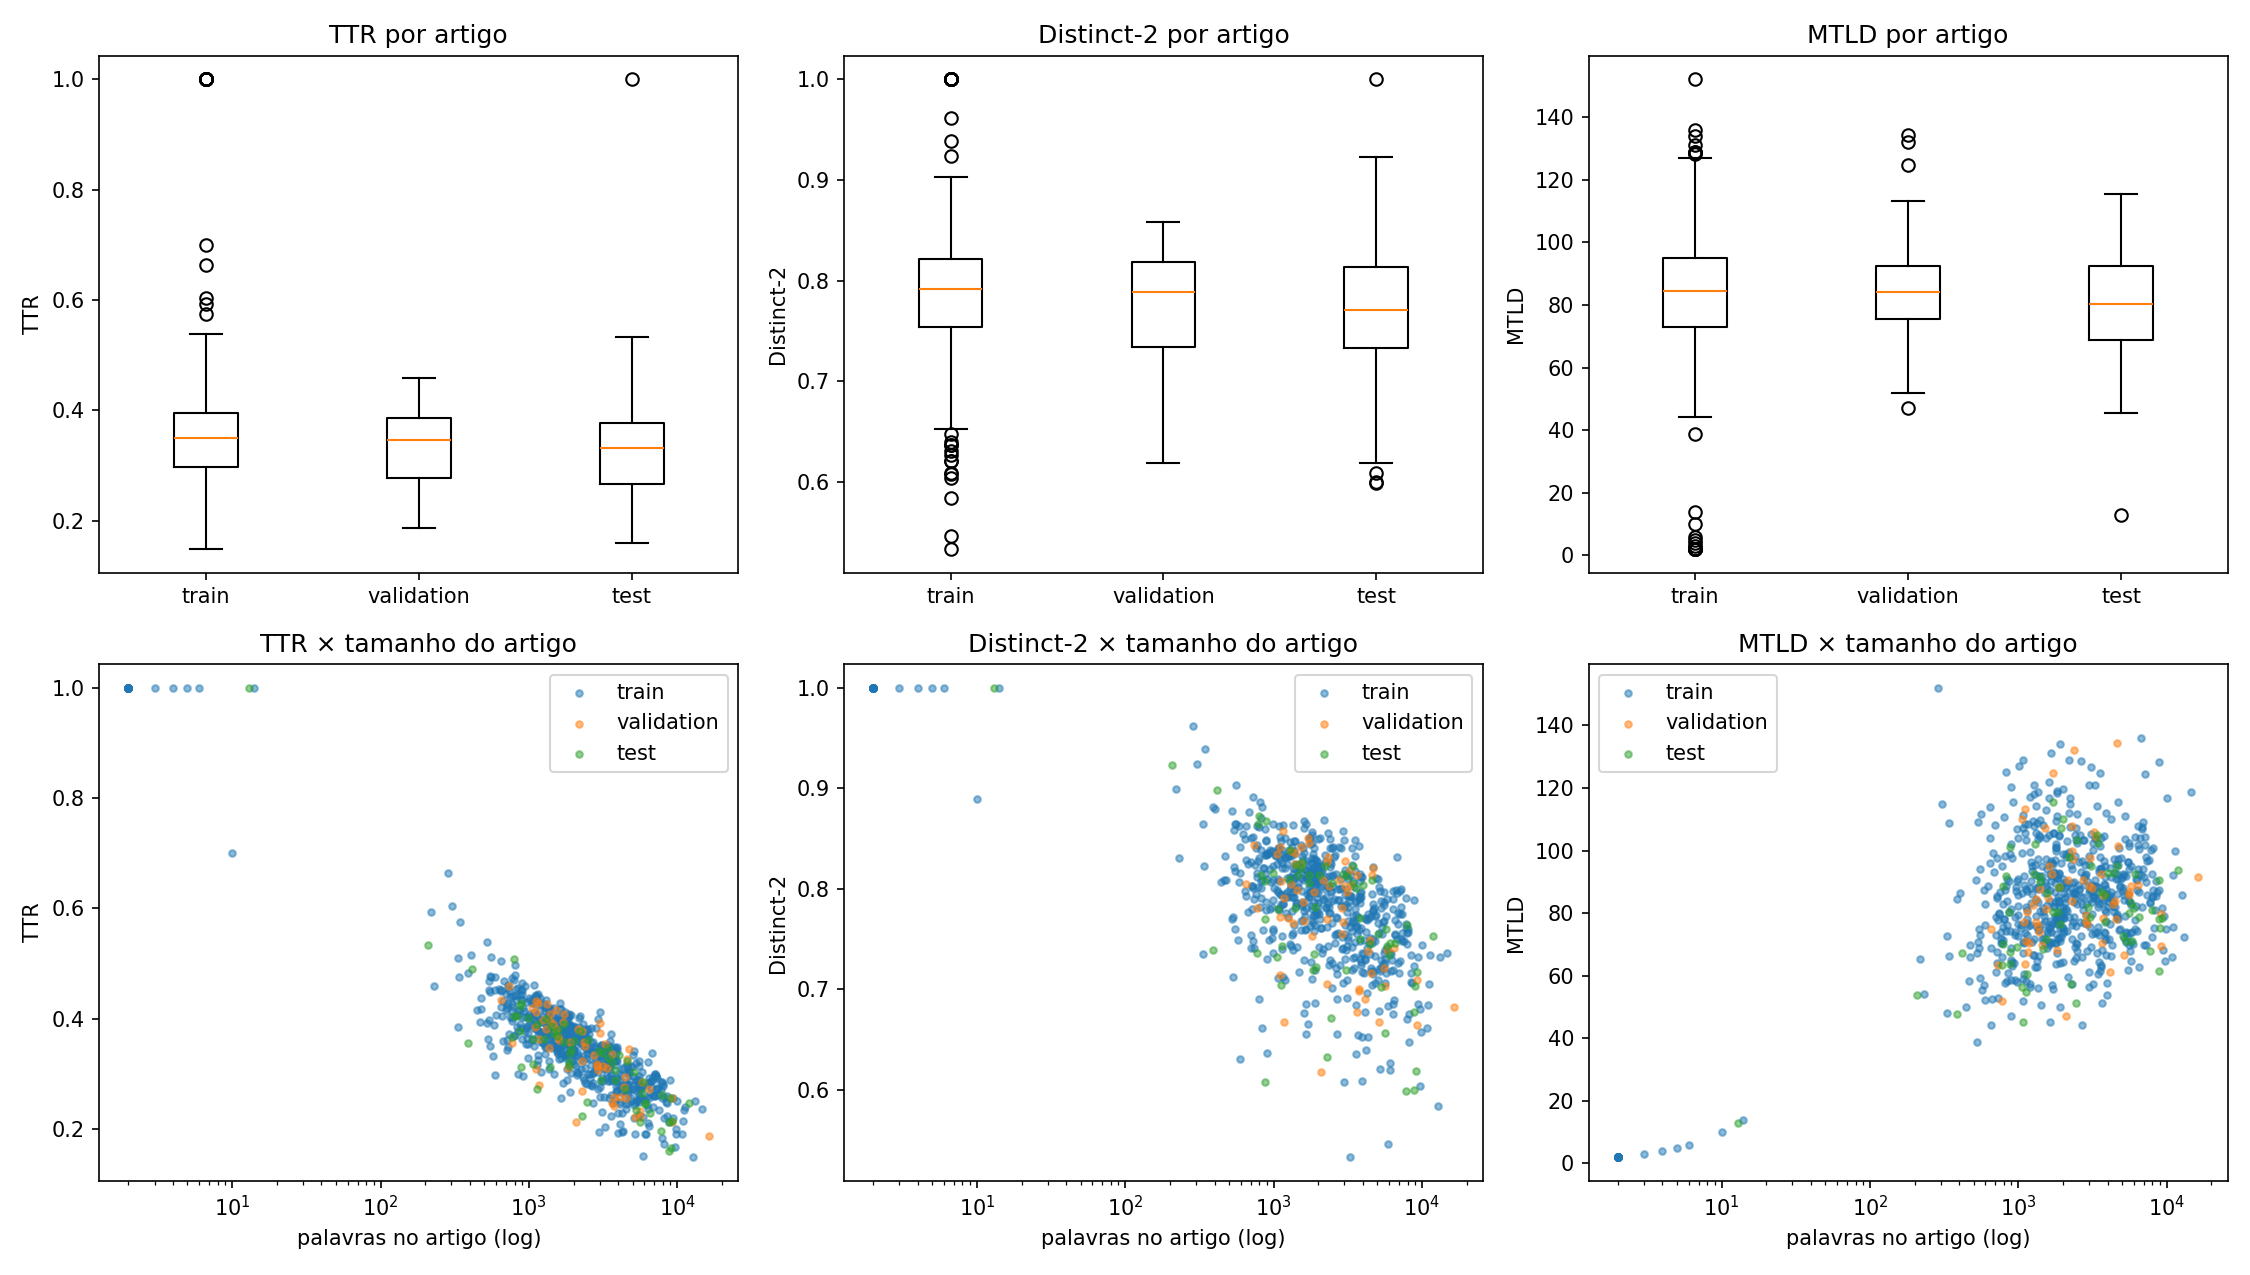

In [25]:
from IPython.display import Image, display

display(Image("atv2/diversidade.png", width=1000))

#### Análise

#### Resultados dos boxplots

**TTR por artigo.** As medianas são próximas nas três partições (cerca de 0,35 no treino e na validação e 0,33 no teste). O valor indica que, num artigo típico, apenas cerca de um terço das palavras são distintas, o que é esperado em textos longos, nos quais as palavras comuns se repetem muitas vezes.

**Distinct-2 por artigo.** As medianas ficam em torno de 0,77 a 0,79. Ou seja, cerca de 80% dos pares de palavras consecutivas de um artigo são únicos. O valor é bem maior que o TTR porque pares de palavras se repetem muito menos do que palavras isoladas: "the" aparece centenas de vezes num artigo, mas o par "the album" aparece poucas. Os *outliers* inferiores (de 0,53 a 0,65) são artigos com estrutura repetitiva, como listas, tabelas de resultados esportivos ou votações (como os resultados do conclave identificados na análise de redundância), em que as mesmas sequências se repetem com pequenas variações.

**MTLD por artigo.** As medianas são de cerca de 84 no treino e na validação e de 80 no teste, com caixas de alturas semelhantes. Como o MTLD é pouco sensível ao tamanho do texto, ele é a medida mais confiável para comparar as partições e confirma que a **diversidade lexical é equivalente** entre elas.

**Os valores atípicos extremos.** No treino e no teste, há artigos com TTR e Distinct-2 iguais a 1,0 (diversidade "perfeita") e com MTLD próximo de zero. Esses valores contraditórios têm a mesma origem: os gráficos inferiores mostram que esses pontos correspondem a "artigos" com menos de 15 palavras. Num texto tão curto, todas as palavras são diferentes (TTR = 1), mas não há texto suficiente para o MTLD ser calculado de forma confiável. São os mesmos trechos que causaram o excesso de artigos na separação (629 em vez de 600 no treino). A validação, que não tem esses trechos, também não tem *outliers* extremos. Em uma análise futura, seria recomendável **descartar textos muito curtos** (por exemplo, com menos de 100 palavras) antes de calcular as medidas de diversidade.

#### Relação com o tamanho do artigo (gráficos inferiores)

Os gráficos inferiores mostram cada medida em função do número de palavras do artigo e confirmam o que a teoria prevê:

- O **TTR cai fortemente** à medida que o artigo cresce, de cerca de 0,5 em artigos de 300 palavras para cerca de 0,2 em artigos de 10.000 palavras. Isso mostra que o TTR mede, em grande parte, o **tamanho** do texto, e não apenas a sua diversidade.
- O **Distinct-2 também cai** com o tamanho, mas de forma mais suave e com mais dispersão.
- O **MTLD não diminui** com o tamanho. Os pontos formam uma nuvem horizontal entre cerca de 50 e 130, ou seja, artigos curtos e longos podem ter diversidade alta ou baixa. Essa independência do tamanho é justamente o objetivo para o qual o MTLD foi criado (MCCARTHY; JARVIS, 2010).

Esses resultados explicam por que o TTR médio da validação e do teste é um pouco menor que o do treino: os artigos dessas partições são, em média, mais longos. Quando a diversidade é medida pelo MTLD, essa diferença desaparece.

#### Síntese

As três partições do WikiText-2 têm diversidade lexical semelhante, com artigos que usam um vocabulário variado e poucas repetições de sequências. Entre as medidas utilizadas, o **MTLD** é a mais adequada para comparar textos de tamanhos diferentes, enquanto o TTR e o Distinct-N devem ser interpretados sempre junto com o tamanho do texto. Os valores atípicos extremos não refletem a diversidade real do corpus, e sim trechos curtos que não correspondem a artigos completos.

#### *2.2. Diversidade semântica do dataset*

As medidas de diversidade lexical (TTR, Distinct-N e MTLD) avaliam apenas a variedade de palavras. Para avaliar também a variedade entre as frases, usei asduas medidas complementares que foram sugeridas: self-BLEU e similaridade por embbedings. Os resultados podem ser gerados através do arquivo *semantica.py*.

**BLEU** (*Bilingual Evaluation Understudy*) foi criado para avaliar tradução automática. Ele compara um texto com um ou mais textos de referência e mede a proporção de n-gramas (sequências de 1 a 4 palavras) que eles têm em comum. O resultado vai de 0 (nenhuma sobreposição) a 1 (textos idênticos) (PAPINENI et al., 2002) [5].

**Self-BLEU** usa o BLEU para medir a diversidade de um conjunto de textos, comparando-o consigo mesmo. Cada frase é avaliada usando todas as outras frases do conjunto como referência, e o resultado é a média desses valores (ZHU et al., 2018) [6]. Um Self-BLEU **alto** indica que as frases repetem os mesmos trechos, ou seja, **pouca diversidade**. Por se basear em palavras iguais, o Self-BLEU não reconhece frases que dizem a mesma coisa com palavras diferentes.

**Similaridade por embeddings** compara o **significado** das frases. Cada frase é transformada em um vetor numérico (*embedding*) por um modelo de linguagem, de modo que frases com sentidos parecidos ficam próximas no espaço vetorial. A similaridade entre duas frases é o cosseno do ângulo entre os seus vetores, que vai de -1 a 1. Usei o modelo `all-MiniLM-L6-v2`, da biblioteca `sentence-transformers`, e calculei a média do cosseno entre todos os pares de frases. Assim como no Self-BLEU, um valor **alto** indica **pouca diversidade**.

Em cada partição, sorteei 500 frases com pelo menos 5 palavras e calculei o Self-BLEU-4 e a similaridade média entre todos os pares.

**Tabela – Diversidade semântica por partição (500 frases por partição)**

| Partição | Self-BLEU | Similaridade por embeddings |
|---|---:|---:|
| Treino | 0,068 | 0,026 |
| Validação | 0,078 | 0,036 |
| Teste | 0,084 | 0,039 |

As três partições apresentam valores muito baixos nas duas medidas, o que indica **alta diversidade**: as frases quase não compartilham sequências de palavras e tratam de assuntos bem diferentes entre si. Isso é esperado num corpus formado por artigos da Wikipédia sobre temas variados.

O treino é a partição mais diversa nas duas medidas. Uma explicação provável é que as frases do treino foram sorteadas entre cerca de 600 artigos, enquanto as da validação e do teste vêm de apenas cerca de 60. Com menos artigos, é mais comum sortear frases do mesmo artigo, que compartilham assunto e vocabulário, o que aumenta um pouco a similaridade.


#### *2.4. Diversidade temática: número de tópicos, distribuição dos assuntos e entropia temática.*

Enquanto as análises lexical e semântica avaliam palavras e frases, a diversidade temática avalia os **assuntos** abordados pelo corpus. Ela é importante porque um corpus pode ter vocabulário rico e frases variadas e, ainda assim, se concentrar em poucos temas. Um modelo de linguagem treinado nesse corpus tende a aprender bem esses temas e mal os demais. A análise tem três frentes:

- **Número de tópicos**: indica quantos assuntos distintos existem no corpus. Os tópicos são identificados automaticamente por um modelo de tópicos, como o LDA (*Latent Dirichlet Allocation*), que agrupa palavras que costumam aparecer juntas. Essa frente mostra a **amplitude** do corpus, isto é, quantos temas diferentes ele cobre.

- **Distribuição dos assuntos**: mostra a proporção do corpus dedicada a cada tópico. Ela revela se alguns temas dominam o conjunto de dados e se outros aparecem pouco. Essa frente mostra o **equilíbrio** entre os temas e ajuda a identificar possíveis vieses do corpus.

- **Entropia temática**: resume a distribuição dos assuntos em um único número, aplicando a entropia de Shannon às proporções dos tópicos. A entropia é baixa quando o corpus se concentra em poucos temas e alta quando os temas estão distribuídos de forma equilibrada. Normalizada pelo número de tópicos, ela varia entre 0 e 1, o que permite comparar partições e artigos diferentes.

Em conjunto, as três frentes respondem a três perguntas complementares: **quantos** assuntos existem, **como** o corpus se divide entre eles e **o quão equilibrada** é essa divisão.



#### Resultados da diversidade temática

Treinei o LDA nos 629 artigos do treino, com um vocabulário de **13.516 palavras**, depois de remover as *stopwords*, as palavras presentes em menos de 5 artigos e as presentes em mais de 50% deles. A validação e o teste foram projetados nos mesmos tópicos.

#### 1. Número de tópicos

**Tabela – Escolha do número de tópicos (K)**

| K | Coerência NPMI | Perplexidade (validação) |
|---:|---:|---:|
| 5 | 0,205 | 13.115,9 |
| **8** | **0,246** | **18.885,8** |
| 10 | 0,229 | 22.859,8 |
| 15 | 0,222 | 36.490,2 |
| 20 | 0,199 | 56.606,5 |
| 25 | 0,182 | 85.714,3 |
| 30 | 0,185 | 120.831,1 |

A maior coerência foi obtida com **K = 8**. As diferenças entre os valores de K são pequenas (de 0,18 a 0,25), então o valor exato de K não deve ser interpretado como o "número real" de assuntos do corpus. O critério mais importante é que os tópicos obtidos sejam interpretáveis. A perplexidade aumentou com K, o que indica que, com apenas 629 documentos, modelos com mais tópicos se ajustam demais ao treino. Por isso, usei a perplexidade apenas como apoio.

**Tabela – Tópicos encontrados (K = 8)**

| Tópico | Palavras mais prováveis | Interpretação |
|---|---|---|
| T0 | game, film, series, episode, games, character, released, hero | Jogos, filmes e séries |
| T1 | century, ireland, english, events, parliament, irish, england | História da Irlanda e da Inglaterra |
| T2 | storm, tropical, hurricane, species, km, winds, star, damage | Fenômenos naturais (furacões, espécies, astronomia) |
| T3 | river, dam, song, missouri, south, north, area, birds, water | Geografia e rios (tópico misto) |
| T4 | city, church, century, state, road, highway, university, built | Cidades, construções e estradas |
| T5 | season, team, game, league, club, won, final, match | Esportes |
| T6 | song, album, music, said, songs, wrote, released, video | Música |
| T7 | war, british, german, army, military, forces, battalion, ship | Guerra e história militar |

A maioria dos tópicos é claramente interpretável, com destaque para esportes (T5), música (T6) e guerra (T7). Os tópicos T2 e T3 são menos coerentes: o T2 mistura furacões, espécies e estrelas, e o T3 mistura rios com palavras como *song* e *birds*. Isso sugere que temas menos frequentes no corpus acabaram agrupados por falta de tópicos disponíveis.


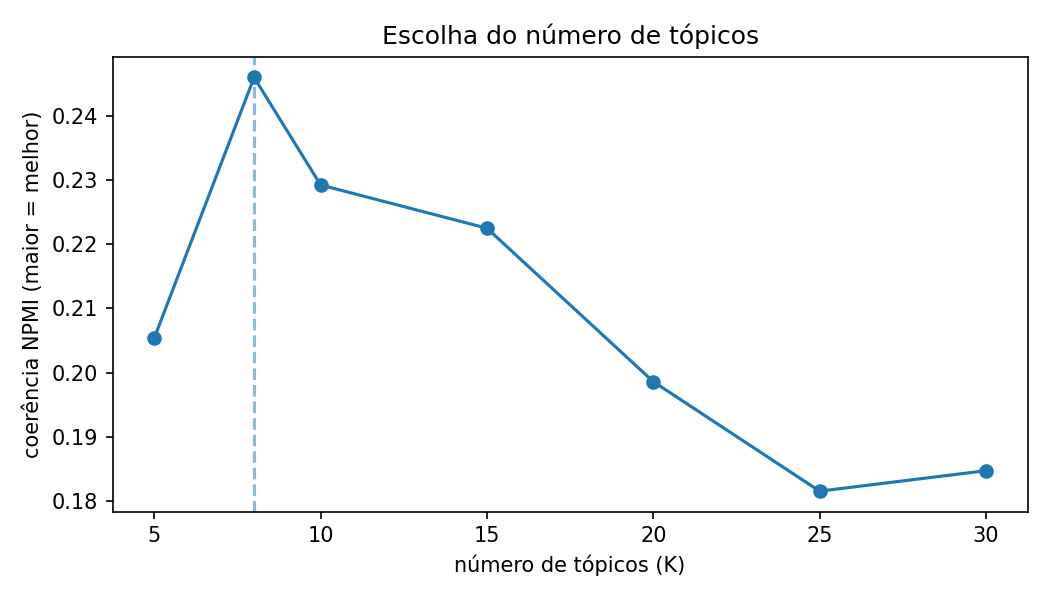

In [15]:
from IPython.display import Image, display

display(Image("atv2/tematica_k.png", width=600))


#### 2. Distribuição dos assuntos

**Tabela – Porcentagem de artigos em que cada tópico é o dominante**

| Tópico | Treino (%) | Validação (%) | Teste (%) |
|---|---:|---:|---:|
| T0 – Jogos, filmes e séries | 12,6 | 10,0 | 6,5 |
| T1 – História Irlanda/Inglaterra | 5,7 | 0,0 | 1,6 |
| T2 – Fenômenos naturais | 10,8 | 10,0 | 14,5 |
| T3 – Geografia e rios | 5,2 | 6,7 | 0,0 |
| T4 – Cidades e construções | 15,1 | 18,3 | 17,7 |
| T5 – Esportes | 11,9 | 10,0 | 12,9 |
| T6 – Música | **25,6** | **26,7** | **24,2** |
| T7 – Guerra | 13,0 | 18,3 | 22,6 |

Todos os 8 tópicos dominam ao menos um artigo do treino. O resultado mais relevante é o peso de **música (T6)**, dominante em cerca de um quarto dos artigos nas três partições, seguida por cidades (T4) e guerra (T7). Isso mostra que o WikiText-2 não é uma amostra neutra da Wikipédia: ele é formado por artigos "bons" e "em destaque" (MERITY et al., 2017), categorias em que temas como cultura pop, esportes e história militar são muito frequentes. Um modelo treinado nesse corpus tende a ver muito mais textos sobre esses assuntos do que sobre ciência ou economia, por exemplo.

As diferenças entre as partições devem ser lidas com cautela. A validação e o teste têm cerca de 60 artigos cada, então um único artigo vale cerca de 1,7%. Os valores de 0% para T1 e T3 refletem o tamanho pequeno dessas partições, não a ausência real desses temas.

#### 3. Entropia temática

**Tabela – Entropia temática por artigo (normalizada, de 0 a 1)**

| Partição | Média | Mediana | Desvio | Mínimo | Máximo |
|---|---:|---:|---:|---:|---:|
| Treino | 0,342 | 0,344 | 0,223 | 0,001 | 0,854 |
| Validação | 0,491 | 0,501 | 0,182 | 0,100 | 0,801 |
| Teste | 0,496 | 0,528 | 0,180 | 0,079 | 0,770 |

**Tabela – Entropia temática por partição (distribuição dos artigos entre os tópicos)**

| Partição | H (bits) | H normalizada |
|---|---:|---:|
| Treino | 2,85 | 0,949 |
| Validação | 2,66 | 0,888 |
| Teste | 2,56 | 0,853 |

*Máximo possível: log₂(8) = 3,00 bits.*

**Por partição**, a entropia normalizada é alta nas três partições (de 0,85 a 0,95). Os artigos se distribuem de forma bastante equilibrada entre os tópicos, o que indica **alta diversidade temática** do corpus como um todo, apesar do predomínio de música. Os valores um pouco menores na validação e no teste são esperados, por terem menos artigos.

**Por artigo**, a entropia média do treino (0,34) é menor que a da validação e do teste (cerca de 0,49). Essa diferença, porém, é um efeito do método, e não uma característica dos dados. Como o LDA foi treinado no treino, ele se ajusta melhor a esses artigos e atribui a eles misturas de tópicos mais concentradas. Os artigos da validação e do teste, nunca vistos pelo modelo, recebem misturas mais espalhadas. Por isso, essa comparação entre partições não deve ser usada como evidência de diferença temática.

**Tabela – Artigos mais focados e mais mistos (treino)**

| Tipo | Entropia | Artigo | Tópico dominante |
|---|---:|---|---|
| Focado | 0,00 | Missouri River | T3 – Geografia e rios |
| Focado | 0,00 | 1990 Pacific hurricane season | T2 – Fenômenos naturais |
| Focado | 0,00 | 2010 Alabama Crimson Tide football team | T5 – Esportes |
| Misto | 0,85 | Frederick Reines | – |
| Misto | 0,82 | Edward Creutz | – |
| Misto | 0,82 | Berkley Bedell | – |

Os artigos mais focados confirmam que os tópicos fazem sentido: um rio, uma temporada de furacões e um time de futebol americano caem integralmente nos tópicos esperados. Os artigos mais mistos também são informativos. Frederick Reines e Edward Creutz são **físicos**, e nenhum dos 8 tópicos corresponde a ciência. Por isso, esses artigos se espalham entre vários tópicos. Ou seja, a entropia alta pode indicar não só um artigo com muitos assuntos, mas também um **tema pouco representado** no corpus, que o modelo não conseguiu isolar.

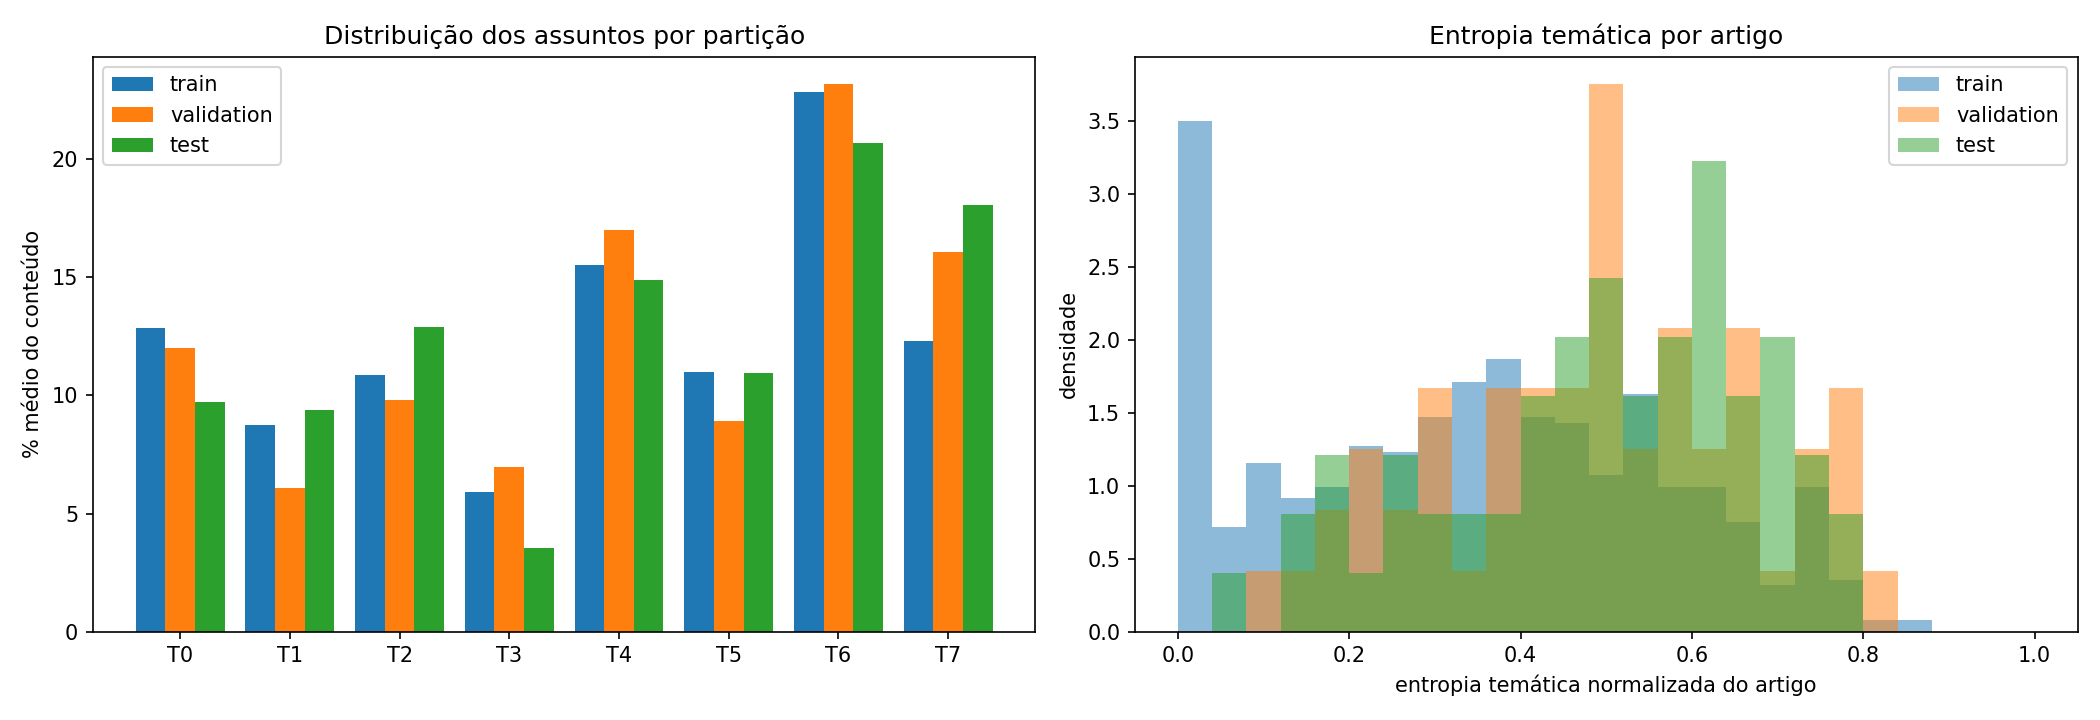

In [18]:
from IPython.display import Image, display

display(Image("atv2/tematica.png", width=900))

#### Síntese

Os resultados mais relevantes desta análise são:
- os **tópicos interpretáveis**, que mostram os principais temas do corpus;
- o **predomínio de música, cidades e guerra**, que revela um viés temático do WikiText-2;
- a **entropia por partição alta**, que indica diversidade temática equilibrada;
- os **artigos mistos**, que apontam a sub-representação de temas como ciência.

São menos relevantes:
- o valor exato de K, porque as diferenças de coerência são pequenas;
- a perplexidade, porque não é confiável com tão poucos documentos;
- as porcentagens dos tópicos raros na validação e no teste, por causa do tamanho pequeno das partições;
- a comparação da entropia por artigo entre as partições, porque é um efeito do método.

#### *2.5. Redundância e Características Textuais*

*Redundância*

A análise de redundância identifica textos **duplicados** (idênticos ou quase idênticos) e textos **semanticamente semelhantes** (que dizem a mesma coisa com palavras diferentes). Ela é relevante por três motivos:

- **Memorização**: quando um mesmo trecho aparece várias vezes no treino, o modelo tende a decorá-lo em vez de aprender padrões gerais da língua. Remover duplicatas reduz a memorização e melhora a generalização dos modelos de linguagem (LEE et al., 2022) [7].
- **Vazamento entre partições**: se um texto do teste também aparece no treino, o modelo é avaliado em algo que já viu. Isso torna as métricas de avaliação, como a perplexidade, artificialmente melhores do que o desempenho real.
- **Diversidade efetiva**: o tamanho de um corpus pode enganar. Um conjunto de dados grande, mas cheio de repetições, contém menos informação nova do que aparenta. A redundância mostra quanto do corpus é de fato conteúdo distinto.

A identificação de duplicatas exatas mede a repetição na **forma**, enquanto a semelhança semântica (por exemplo, por embeddings) mede a repetição no **conteúdo**. As duas são complementares.

*Características textuais*

As características textuais descrevem o perfil básico dos textos do corpus e ajudam a entender o que um modelo vai aprender com ele:

- **Comprimento**: o número de palavras e de frases por texto. Ele define, por exemplo, o tamanho de contexto necessário para o modelo e como os textos serão divididos em sequências de treino. Textos muito curtos podem ser ruído (como listas ou fragmentos), e textos muito longos podem dominar o treino.
- **Frequência de palavras**: mostra quais palavras são comuns e quais são raras. Pela Lei de Zipf, poucas palavras cobrem a maior parte do texto, enquanto muitas aparecem pouquíssimas vezes. Isso afeta diretamente a escolha do vocabulário e da tokenização, e explica a existência de palavras fora do vocabulário (OOV) na validação e no teste.
- **Complexidade lexical**: avalia o quão rico e variado é o vocabulário, por medidas como TTR e MTLD. Um corpus com alta complexidade lexical expõe o modelo a mais palavras e construções diferentes, mas também torna a tarefa de modelagem mais difícil.

Em conjunto, essas medidas permitem caracterizar o WikiText-2 e comparar as partições entre si, verificando se o treino, a validação e o teste têm perfis semelhantes, condição necessária para que a avaliação do modelo seja confiável.

#### **Resultados: redundância e características textuais**

####  - Redundância exata

**Tabela – Duplicatas exatas e vazamento entre partições**

| Partição | Parágrafos duplicados (%) | Frases duplicadas (%) | Parágrafos também no treino (%) | Frases também no treino (%) |
|---|---:|---:|---:|---:|
| Treino | 0,13 | 0,17 | – | – |
| Validação | 0,00 | 0,12 | 0,00 | 0,18 |
| Teste | 0,10 | 0,22 | 0,00 | 0,04 |

A redundância exata do WikiText-2 é **muito baixa**: apenas 0,13% dos parágrafos e 0,17% das frases do treino se repetem. Os parágrafos mais repetidos não são erros de coleta, e sim textos legitimamente recorrentes. Exemplos são notas padronizadas de tabelas esportivas ("*Note: flags indicate national team as defined under FIFA eligibility rules*", "*Pts = points, NRR = net run rate*") e versos que se repetem dentro de um mesmo artigo, como os da cantiga *Jack and Jill*.

O resultado mais importante é a **ausência de vazamento**. Nenhum parágrafo da validação ou do teste aparece no treino, e as frases em comum (0,18% e 0,04%) são poucas e provavelmente curtas e genéricas. Isso garante que o modelo não será avaliado em textos que já viu durante o treino, então métricas como a perplexidade no teste refletem a capacidade real de generalização.

#### - Redundância semântica

**Tabela – Similaridade com o parágrafo mais parecido do treino (embeddings)**

| Comparação | Similaridade mediana | Quase duplicados ≥ 0,95 (%) | Muito semelhantes ≥ 0,85 (%) |
|---|---:|---:|---:|
| Treino × treino | 0,690 | 0,529 | 3,701 |
| Validação × treino | 0,504 | 0,112 | 0,617 |
| Teste × treino | 0,499 | 0,000 | 0,246 |

A redundância semântica também é baixa. Apenas 0,53% dos parágrafos do treino têm um "quase duplicado", e na validação e no teste esse valor é praticamente nulo (0,11% e 0%), o que confirma a ausência de vazamento também no nível do significado.

A similaridade é maior dentro do treino (mediana de 0,69) do que entre a validação ou o teste e o treino (cerca de 0,50). Essa diferença é esperada e não indica redundância. Dentro do treino, o parágrafo mais parecido costuma pertencer ao **mesmo artigo**, que trata do mesmo assunto. Já os artigos da validação e do teste são diferentes dos do treino.

Os pares quase idênticos encontrados mostram um tipo específico de redundância: **dados estruturados escritos como texto**. Por exemplo, os resultados diários de votação de um conclave papal ("*May 8 – Colonna – 9 ; Stoppani – 6 ; ...*" e "*May 9 – Colonna – 11 ; ...*") têm sentido quase idêntico e mudam apenas os números. Esse tipo de conteúdo, comum em listas e tabelas convertidas, ensina pouco sobre a língua ao modelo, mas representa uma parcela muito pequena do corpus.

#### Comprimento e complexidade lexical

**Tabela – Características textuais (média por artigo)**

| Partição | Palavras | Frases | Palavras por frase | Letras por palavra | TTR | MTLD (média) | MTLD (mediana) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Treino | 2.723 | 120,7 | 21,9 | 4,83 | 0,37 | 84,7 | 84,1 |
| Validação | 2.992 | 132,9 | 22,7 | 4,87 | 0,34 | 85,4 | 84,1 |
| Teste | 3.252 | 150,0 | 21,5 | 4,89 | 0,34 | 80,1 | 80,6 |

*O MTLD não pôde ser calculado em 18 artigos do treino e em 1 do teste, por serem curtos demais para que o TTR atingisse o limiar de 0,72.*

Os artigos são **longos**, com cerca de 2.700 a 3.250 palavras em média. Isso é muito mais do que a janela de contexto de modelos pequenos. Na prática, cada artigo precisa ser dividido em várias sequências de treino (por exemplo, com a janela deslizante usada para criar os pares de entrada e alvo de um LLM), e o modelo não "vê" o artigo inteiro de uma vez. As frases são longas (cerca de 22 palavras), típicas do estilo enciclopédico, com muitas orações subordinadas e informações encadeadas.

O comprimento das frases e das palavras é praticamente igual nas três partições, o que indica um **estilo de escrita homogêneo**. O TTR é um pouco menor na validação e no teste (0,34 contra 0,37), mas isso não indica menor riqueza de vocabulário: os artigos dessas partições são mais longos, e o TTR diminui naturalmente com o tamanho do texto. O MTLD, que é pouco sensível ao tamanho, confirma essa interpretação. A mediana é a mesma no treino e na validação (84,1) e apenas um pouco menor no teste (80,6), uma diferença pequena diante da variação entre artigos. Ou seja, a **complexidade lexical é equivalente nas três partições**, e a diferença de TTR é apenas um efeito do comprimento dos textos.

Os 18 artigos do treino sem MTLD definido são textos muito curtos. Eles provavelmente correspondem aos "artigos" extras identificados na etapa de separação (629 encontrados, contra os 600 descritos na literatura). Isso reforça a hipótese de que algumas linhas no formato de título de nível 1 não iniciam artigos reais, mas sim pequenos trechos isolados.

#### Frequência de palavras

**Tabela – Faixas de frequência das palavras no treino (1.712.750 tokens, 75.620 palavras distintas)**

| Faixa de frequência | % do vocabulário | % dos tokens |
|---|---:|---:|
| 1 vez | 45,55 | 2,01 |
| 2–10 | 38,33 | 6,67 |
| 11–100 | 13,43 | 18,70 |
| 101–1.000 | 2,53 | 27,97 |
| > 1.000 | 0,17 | 44,65 |

A distribuição de frequências é extremamente desigual, como prevê a Lei de Zipf. Apenas **0,17% do vocabulário** (cerca de 130 palavras) aparece mais de mil vezes e, sozinho, cobre **44,65% de todo o texto**. No outro extremo, **45,55% das palavras aparecem uma única vez**, mas somam apenas 2% dos tokens.

Essa cauda longa tem consequências diretas para a modelagem. Quase metade do vocabulário aparece uma vez só, e o modelo não tem exemplos suficientes para aprender essas palavras. Incluí-las inteiras no vocabulário seria caro e pouco útil. É por isso que a versão não-raw do WikiText-2 substitui as palavras raras pelo token `<unk>`, e que os LLMs modernos usam tokenização por subpalavras, como o BPE, que representa palavras raras como combinações de partes mais frequentes.

#### Relação entre as análises

Cada análise responde a uma pergunta diferente sobre a adequação do corpus para treinar e avaliar um modelo de linguagem:

| Análise | Pergunta que responde | Resultado no WikiText-2 |
|---|---|---|
| Redundância exata | O modelo vai decorar trechos repetidos? O teste está contaminado? | Repetição mínima e sem vazamento |
| Redundância semântica | Há conteúdo repetido com outras palavras? | Muito baixa; restrita a dados estruturados |
| Comprimento | Como dividir os textos para o treino? | Artigos longos, que exigem janelas de contexto |
| Frequência de palavras | Como montar o vocabulário e a tokenização? | Cauda longa: justifica `<unk>` ou subpalavras |
| Complexidade lexical | O quão difícil é a tarefa de modelagem? | Estilo homogêneo entre as partições |

As análises de **redundância** são as mais importantes para a **confiabilidade da avaliação**: sem vazamento, os resultados no teste são válidos. As **características textuais** são as mais importantes para as **decisões de projeto** do modelo, como o tamanho do contexto, o vocabulário e a tokenização. Em conjunto, os resultados indicam que o WikiText-2 é um corpus limpo, com pouca repetição, partições comparáveis entre si e um estilo de escrita homogêneo, adequado para o treino e a avaliação de modelos de linguagem.

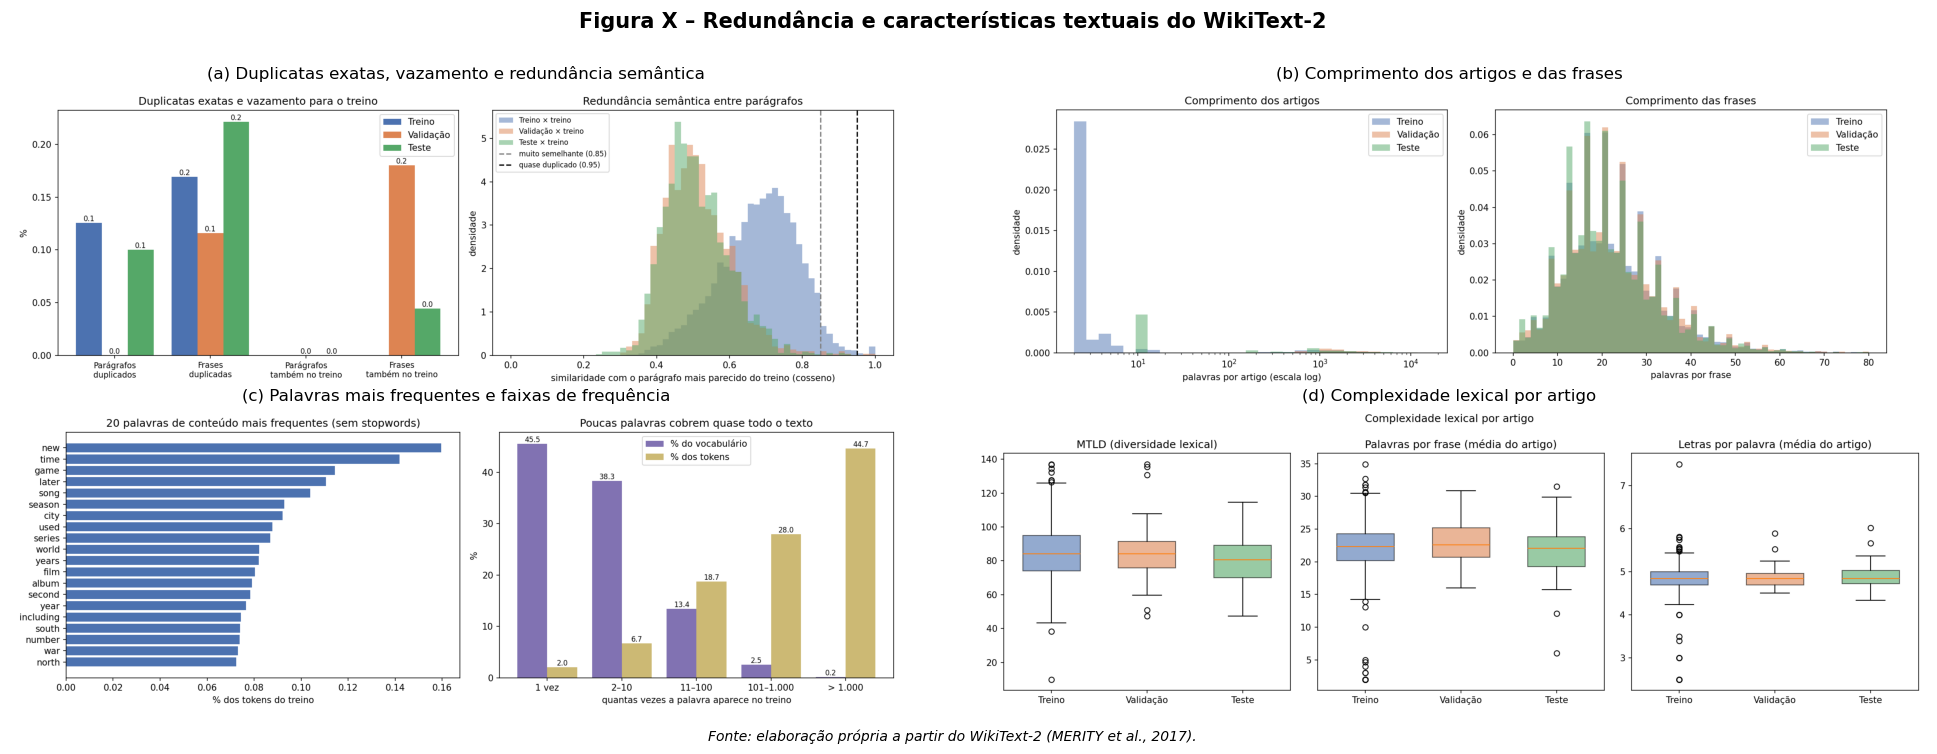

In [21]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

figuras = [
    ("atv2/fig_redundancia.png",  "(a) Duplicatas exatas, vazamento e redundância semântica"),
    ("atv2/fig_comprimento.png",  "(b) Comprimento dos artigos e das frases"),
    ("atv2/fig_frequencia.png",   "(c) Palavras mais frequentes e faixas de frequência"),
    ("atv2/fig_complexidade.png", "(d) Complexidade lexical por artigo"),
]

fig, eixos = plt.subplots(2, 2, figsize=(20, 7.5))
for ax, (arquivo, legenda) in zip(eixos.flat, figuras):
    ax.imshow(mpimg.imread(arquivo))
    ax.set_title(legenda, fontsize=12, pad=6)
    ax.axis("off")

fig.suptitle("Figura X – Redundância e características textuais do WikiText-2",
             fontsize=15, fontweight="bold")
fig.text(0.5, 0.005, "Fonte: elaboração própria a partir do WikiText-2 (MERITY et al., 2017).",
         ha="center", fontsize=10, style="italic")
fig.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

#### Análise

#### Redundância e diversidade: uma visão conjunta

Redundância e diversidade são dois lados da mesma questão: quanto de informação **nova** o corpus oferece ao modelo. Os resultados apontam na mesma direção:

| Aspecto | Resultado | Interpretação |
|---|---|---|
| Duplicatas exatas | < 0,2% | Quase nenhuma repetição literal |
| Vazamento para o treino | 0% dos parágrafos | Avaliação confiável |
| Redundância semântica | Pico de similaridade ~0,5 entre partições | Conteúdo novo também no significado |
| Comprimento das frases | Distribuições sobrepostas | Estilo homogêneo entre as partições |
| Frequência de palavras | Cauda longa (45,5% do vocabulário aparece 1 vez) | Vocabulário amplo e diverso |

O WikiText-2 combina **baixa redundância** com **alta diversidade lexical**: o texto quase não se repete, e o vocabulário é amplo, com uma cauda longa de palavras raras. Essa diversidade, no entanto, convive com uma **concentração temática**. As palavras e os tópicos mais frequentes revelam o predomínio de música, jogos, esportes, geografia e guerra, reflexo da seleção de artigos "bons" e "em destaque" da Wikipédia. O corpus é, portanto, limpo e diverso na forma, mas não é uma amostra neutra de todos os assuntos. Esse ponto deve ser considerado ao interpretar o que um modelo treinado nele aprende.

### 3. Análise crítica e Conclusões

#### 1. O que cada métrica revela sobre o dataset

| Dimensão | Métrica | O que mede | O que revelou no WikiText-2 |
|---|---|---|---|
| Estrutura | Contagem de artigos e títulos | Organização do corpus | 629 / 60 / 62 artigos, acima dos 600 / 60 / 60 oficiais: há trechos curtos com formato de título que não são artigos |
| Comprimento | Palavras e frases por artigo | Tamanho dos textos | Artigos longos (mediana ~2.300 palavras) e distribuição assimétrica, com poucos artigos muito longos |
| Comprimento | Palavras por frase | Estilo de escrita | ~22 palavras por frase, igual nas três partições: estilo enciclopédico homogêneo |
| Frequência | Faixas de frequência, Lei de Zipf | Distribuição do vocabulário | Cauda longa: 45,5% do vocabulário aparece uma vez; 0,2% cobre 44,7% do texto |
| Vocabulário | Taxa de OOV | Palavras do teste ausentes no treino | Sempre haverá palavras novas, o que justifica `<unk>` ou subpalavras |
| Diversidade lexical | TTR, Distinct-N, MTLD | Variedade de palavras e sequências | MTLD ~84 nas três partições: diversidade lexical alta e equivalente |
| Diversidade semântica | Self-BLEU, similaridade por embeddings | Variedade entre frases | Valores muito baixos (Self-BLEU ~0,07; cosseno ~0,03): frases muito diferentes entre si |
| Diversidade temática | LDA, entropia | Variedade de assuntos | 8 tópicos interpretáveis, com predomínio de música, cidades e guerra |
| Redundância | Duplicatas exatas e semânticas | Repetição e vazamento | Redundância < 0,2% e nenhum vazamento de parágrafos para o treino |

Cada métrica olha para um nível diferente do texto: caracteres e palavras, sequências, frases, assuntos e documentos. Nenhuma delas, sozinha, descreve o corpus. É a combinação que permite concluir que o WikiText-2 é **limpo, pouco redundante e lexicalmente diverso, mas tematicamente enviesado**.

#### 2. Métricas diferentes podem produzir conclusões contraditórias?

Sim. Isso aconteceu várias vezes neste trabalho. Em todos os casos, a contradição não indicava erro, e sim que **cada métrica é sensível a fatores diferentes**:

- **TTR × MTLD.** O TTR sugeria que a validação e o teste eram menos diversos que o treino (0,34 contra 0,37). O MTLD mostrou que a diversidade é equivalente (~84). A diferença de TTR vinha apenas de os artigos dessas partições serem mais longos, pois o TTR mede, em grande parte, o tamanho do texto.
- **Diversidade "perfeita" × diversidade nula.** Os trechos de 2 a 15 palavras tiveram TTR e Distinct-2 iguais a 1,0 e MTLD próximo de zero. As duas leituras são falsas: textos tão curtos simplesmente não têm informação suficiente para nenhuma das medidas.
- **Entropia temática por artigo × por partição.** Por artigo, o treino parecia tematicamente mais focado (0,34 contra 0,49). Por partição, o treino era o mais equilibrado (0,95). A primeira diferença é um efeito do método: o LDA foi treinado no treino e se ajusta melhor a esses artigos.
- **Similaridade semântica.** O treino parecia mais redundante (similaridade mediana de 0,69 contra 0,50), mas isso ocorre porque, dentro do treino, o vizinho mais parecido de um parágrafo costuma ser do mesmo artigo.
- **Lei de Zipf.** A inclinação ajustada (−1,37) sugeria um desvio forte da lei, mas o gráfico mostrava os dados paralelos à reta ideal (−1). O ajuste era dominado pela cauda de palavras raras.
- **Média × mediana.** As médias de comprimento sugeriam diferenças entre as partições (2.723 a 3.252 palavras), mas as medianas eram próximas. As diferenças vinham de poucos artigos muito longos.

A lição é que **nenhuma métrica deve ser interpretada isoladamente**. Antes de concluir algo, é preciso perguntar a que cada medida é sensível (tamanho do texto, conjunto de referência, método de treino, valores extremos) e verificar se a conclusão se mantém com uma medida diferente.

#### 3. Alta diversidade lexical implica alta diversidade semântica?

Não necessariamente. As duas dimensões são independentes em princípio:

- **Diversidade lexical alta com diversidade semântica baixa:** um texto pode dizer a mesma coisa de muitas formas diferentes, como "the film was a success", "the movie achieved great acclaim" e "the picture was well received". O vocabulário é variado, mas o significado se repete.
- **Diversidade lexical baixa com diversidade semântica alta:** frases curtas com palavras comuns podem tratar de assuntos totalmente diferentes, como "the war ended in 1945" e "the song reached number one".

Além disso, as métricas usadas medem coisas em escalas diferentes. O MTLD mede a variedade de palavras **dentro** de cada artigo, enquanto a similaridade por embeddings mede a diferença de significado **entre** frases de artigos distintos. Um artigo pode ser lexicalmente rico e, ao mesmo tempo, tratar de um único assunto do início ao fim.

No WikiText-2, as duas dimensões foram altas ao mesmo tempo, mas isso é uma característica deste corpus, formado por artigos bem escritos sobre temas variados, e não uma regra geral. O caso do conclave papal mostra a independência entre elas: os parágrafos de votação usam as mesmas palavras (baixa diversidade lexical entre eles) e também têm o mesmo significado (baixa diversidade semântica), mas o resto do corpus não tem esse padrão.

#### 4. Uma distribuição equilibrada de tópicos significa boa cobertura temática?

Não. A entropia temática alta (0,95 no treino) mostra que os artigos se distribuem de forma equilibrada **entre os tópicos que o próprio LDA encontrou**, mas não diz nada sobre os assuntos que ficaram de fora:

- **A análise é circular.** Os tópicos são extraídos do próprio corpus. Um tema ausente no WikiText-2 nunca vira tópico e, portanto, não reduz a entropia. Um corpus só sobre esportes, dividido em "futebol", "basquete" e "tênis", também poderia ter entropia máxima.
- **A granularidade depende de K.** Com apenas 8 tópicos, temas distintos foram agrupados. O T2 juntou furacões, espécies e estrelas. Já os físicos Frederick Reines e Edward Creutz ficaram espalhados entre vários tópicos porque não há um tópico de ciência. A entropia alta desses artigos indicava um **tema sub-representado**, e não um artigo com muitos assuntos.
- **O equilíbrio é relativo à seleção.** O WikiText-2 foi construído a partir de artigos "bons" e "em destaque" da Wikipédia (MERITY et al., 2017). Temas como música, jogos e história militar são muito comuns nessas categorias, enquanto áreas como ciência, economia ou medicina aparecem pouco. Um corpus pode ser equilibrado dentro do recorte e, ainda assim, enviesado em relação ao mundo.

Para avaliar a **cobertura** de verdade, seria necessário comparar os temas do corpus com uma **referência externa**, como as categorias da Wikipédia, uma taxonomia de áreas do conhecimento ou outro corpus usado como padrão. Equilíbrio é uma propriedade interna. Cobertura exige um termo de comparação.

#### 5. Limitações das abordagens utilizadas

**Pré-processamento**
- A separação por expressão regular gerou cerca de 30 "artigos" falsos, que não foram removidos e afetaram as estatísticas de comprimento, diversidade e entropia.
- A contagem de palavras por espaço e a separação de frases pelo ponto final são aproximações. Listas, tabelas e títulos sem ponto viram "frases" muito longas, e escolhas como converter para minúsculas e remover a pontuação alteram os resultados.
- As análises foram feitas sobre **palavras**, enquanto os LLMs modernos trabalham com **subpalavras** (BPE). A diversidade e a cauda longa seriam diferentes no nível dos tokens que o modelo realmente vê.

**Métricas de diversidade lexical**
- O TTR e o Distinct-N dependem fortemente do tamanho do texto.
- O MTLD depende de um limiar convencional (0,72), não é definido para textos curtos e tem implementações que variam entre bibliotecas.

**Métricas semânticas**
- O Self-BLEU e a similaridade foram calculados sobre uma amostra de 500 frases, com uma única semente e sem intervalo de confiança. Outra amostra poderia gerar valores um pouco diferentes.
- O Self-BLEU continua sendo uma medida de sobreposição de palavras, e não de significado.
- O resultado dos embeddings depende do modelo escolhido (`all-MiniLM-L6-v2`), que corta textos longos e pode ter sido treinado com dados da própria Wikipédia. Os limiares de 0,85 e 0,95 para "semelhante" e "quase duplicado" são arbitrários.

**Modelagem de tópicos**
- O LDA ignora a ordem das palavras, foi treinado com apenas 629 documentos e numa única execução. A escolha de K = 8 se baseou em diferenças pequenas de coerência.
- A interpretação dos tópicos foi feita manualmente e é, em parte, subjetiva.

**Análise estatística**
- As comparações entre partições foram feitas por inspeção visual e por estatísticas descritivas, sem testes de hipótese. Diferenças pequenas, como o MTLD de 80 no teste contra 84 no treino, podem não ser significativas.
- O ajuste da Lei de Zipf por mínimos quadrados em todos os *ranks* é sensível à cauda e não é o método mais robusto para leis de potência (NEWMAN, 2005).

**Ausência de referência**
- Termos como "alta diversidade" e "baixa redundância" foram usados sem comparar o WikiText-2 com outro corpus. Uma comparação com o WikiText-103 ou com um corpus de outro domínio daria um ponto de referência mais sólido para essas conclusões.

#### Conclusão

A análise mostrou que o WikiText-2 é um corpus adequado para treinar e avaliar modelos de linguagem. Ele tem redundância mínima, nenhum vazamento entre as partições, estilo homogêneo e vocabulário diverso com a cauda longa típica da língua natural. Ao mesmo tempo, apresenta um viés temático herdado do processo de seleção dos artigos.

A principal lição metodológica é que **métricas diferentes respondem a perguntas diferentes** e podem parecer contraditórias quando não se considera a que cada uma é sensível. Conclusões confiáveis sobre um dataset exigem combinar várias métricas, entender as suas limitações e, sempre que possível, compará-las com uma referência externa.

### Referências

[1] RASCHKA, Sebastian. Build a large language model (from scratch). Shelter Island, NY: Manning Publications, 2024. ISBN 978-1-63343-716-6.

[2] PIANTADOSI, Steven T. Zipf's word frequency law in natural language: a critical review and future directions. Psychonomic Bulletin & Review, v. 21, n. 5, p. 1112–1130, 2014. DOI: 10.3758/s13423-014-0585-6.

[3] MERITY, Stephen; XIONG, Caiming; BRADBURY, James; SOCHER, Richard. Pointer sentinel mixture models. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS (ICLR), 5., 2017, Toulon. Proceedings [...]. Toulon: ICLR, 2017. Disponível em: https://arxiv.org/abs/1609.07843. Acesso em: 26 nov. 2026.

[4] MCCARTHY, Philip M.; JARVIS, Scott. MTLD, vocd-D, and HD-D: a validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, v. 42, n. 2, p. 381–392, 2010.

[5] PAPINENI, Kishore; ROUKOS, Salim; WARD, Todd; ZHU, Wei-Jing. BLEU: a method for automatic evaluation of machine translation. In: ANNUAL MEETING OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS (ACL), 40., 2002, Philadelphia. Proceedings [...]. Philadelphia: Association for Computational Linguistics, 2002. p. 311–318. DOI: 10.3115/1073083.1073135.

[6] ZHU, Yaoming; LU, Sidi; ZHENG, Lei; GUO, Jiaxian; ZHANG, Weinan; WANG, Jun; YU, Yong. Texygen: a benchmarking platform for text generation models. In: INTERNATIONAL ACM SIGIR CONFERENCE ON RESEARCH AND DEVELOPMENT IN INFORMATION RETRIEVAL, 41., 2018, Ann Arbor. Proceedings [...]. New York: Association for Computing Machinery, 2018. p. 1097–1100. DOI: 10.1145/3209978.3210080.

[7] LEE, Katherine; IPPOLITO, Daphne; NYSTROM, Andrew; ZHANG, Chiyuan; ECK, Douglas; CALLISON-BURCH, Chris; CARLINI, Nicholas. Deduplicating training data makes language models better. In: ANNUAL MEETING OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS (ACL), 60., 2022, Dublin. *Proceedings* [...]. Dublin: Association for Computational Linguistics, 2022. p. 8424–8445.